# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights
---

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


**1. Import dependencies**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**2. Load Dataset**

In [2]:
# Define the relative file
dataset_path = r".\amazon dataset\amz_uk_price_prediction_dataset.csv"  #   'r' prefix ensures the backslashes are treated correctly

# Load the dataset into a pandas DataFrame
df = pd.read_csv(dataset_path)

# Display the first 5 rows of the dataset to verify it loaded correctly
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


**3. Dataset Overview**

In [3]:
# Display the DataFrame
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [5]:
# Create a list of existing column names
cols_list = list(df.columns)

print(cols_list)
new_cols_list = []

for col in cols_list:
    
    # Clean the column name
    cleaned_col = col.strip().lower()
    
    # Rename specific columns
    if cleaned_col == "isbestseller":
        cleaned_col = "bestseller"
    elif cleaned_col == "boughtinlastmonth":
        cleaned_col = "lastmonth"
    
    # Append cleaned name to new list
    new_cols_list.append(cleaned_col)

# Print new column list
print(new_cols_list)

# Assign the cleaned column names back to the DataFrame
df.columns = new_cols_list


['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'bestseller', 'lastmonth', 'category']


In [6]:
df.head()

,uid,asin,title,stars,reviews,price,bestseller,lastmonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
# Display the shape of the DataFrame
df.shape

(2443651, 9)

In [8]:
# Display columns of the DataFrame
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'bestseller',
       'lastmonth', 'category'],
      dtype='object')

In [9]:
# Display columns datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column      Dtype  
---  ------      -----  
 0   uid         int64  
 1   asin        object 
 2   title       object 
 3   stars       float64
 4   reviews     int64  
 5   price       float64
 6   bestseller  bool   
 7   lastmonth   int64  
 8   category    object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [10]:
# Descriptive statistics
df.describe().T.round(2)        # Round values to two decimals

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
lastmonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


In [11]:
# Create a boolean DataFrame indicating missing (NaN/None) values
missing_counts = pd.isnull(df).sum()

# Sum the missing-value counts across all columns to get a total
total_missing_count = missing_counts.sum()   # returns an integer

# Print the total number of missing values in the DataFrame
print("Total missing values in DataFrame:", total_missing_count)

Total missing values in DataFrame: 0


In [12]:
# Check the data type of missing_counts (pandas Series, i.e., 1D structure)
print(type(missing_counts))

# Display the number of missing values for each column (1D Series output)
missing_counts


<class 'pandas.core.series.Series'>


uid           0
asin          0
title         0
stars         0
reviews       0
price         0
bestseller    0
lastmonth     0
category      0
dtype: int64

**Key obesercations**
- **Total Features:** There are 9 features in the dataset. It contains 5 numerical features and 4 categorical features.
- The dataset contains **no missing values**.

---

**Solution 1: Understanding Product Categories**

*Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?*


**1. Frequency Table**
-  Generate a frequency table for the product `category`.
- Which are the top 5 most listed product categories?

In [13]:
df.head()

,uid,asin,title,stars,reviews,price,bestseller,lastmonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [14]:
# Generate a frequency table for product categories
category_frequency_table = df["category"].value_counts(sort= False).reset_index()

print(type(category_frequency_table))

print(category_frequency_table.shape)

# # Rename columns for clarity
category_frequency_table.columns = ["category","listing_count"]

# Display the top 5 most frequent categories
category_frequency_table

<class 'pandas.core.frame.DataFrame'>
(296, 2)


,category,listing_count
0,Hi-Fi Speakers,8745
1,"CD, Disc & Tape Players",8798
2,Wearable Technology,8906
3,Light Bulbs,9183
4,Bathroom Lighting,254
...,...,...
291,Media Streaming Devices,9414
292,Hi-Fi Receivers & Separates,9199
293,"GPS, Finders & Accessories",9349
294,Indoor Lighting,8586


In [15]:
# Filter out top-20 categories using sort_values() methods
top_20_categories = category_frequency_table.sort_values(by= "listing_count", ascending= False).head(20)

# top_20_categories = category_frequency_table.sort_values(by= "listing_count", ascending= False)[:20]

# Create additinal rank column
top_20_categories['rank'] = [(x) for x in range(1, len(top_20_categories)+1)]

# Define new column sequence
cols = ["rank"] + [c for c in top_20_categories.columns if c != "rank"]                 # Output: cols = ["rank", "category", "listing_count"]

# Assign new columns back to DataFrame
top_20_categories = top_20_categories[cols]

# Display top-20 categories
top_20_categories.head(20)

,rank,category,listing_count
23,1,Sports & Outdoors,836265
114,2,Beauty,19312
202,3,"Handmade Clothing, Shoes & Accessories",19229
81,4,Bath & Body,19092
69,5,Birthday Gifts,18978
89,6,Manicure & Pedicure Products,18940
48,7,Skin Care,18769
140,8,Make-up,18756
284,9,Hair Care,18735
31,10,Fragrances,18564


In [16]:
# Filter out top-5 categories
top_5_categories = top_20_categories[:5]
# top_5_categories = top_20_categories.head(5)

# Display top-5 categories
top_5_categories.head()


,rank,category,listing_count
23,1,Sports & Outdoors,836265
114,2,Beauty,19312
202,3,"Handmade Clothing, Shoes & Accessories",19229
81,4,Bath & Body,19092
69,5,Birthday Gifts,18978


In [17]:
# Conceptual Understanding: Series vs DataFrame

# Generate frequency counts for each product category
category_frequency = df["category"].value_counts()

# Confirm the data type and shape (1D structure)
print(type(category_frequency))        # pandas Series (1D)
print(category_frequency.shape)        # (number_of_unique_categories,)

# Display first 5 values of the pandas Series
display(category_frequency.head())

print("--------------------------------\n")

# Convert the pandas Series into a DataFrame (2D structure)
category_frequency_table = pd.DataFrame(category_frequency)

# Confirm the data type and shape (2D structure)
print(type(category_frequency_table))  # pandas DataFrame (2D)
print(category_frequency_table.shape)  # (number_of_unique_categories, 1)

# Display the full DataFrame
display(category_frequency_table)

<class 'pandas.core.series.Series'>
(296,)


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

--------------------------------

<class 'pandas.core.frame.DataFrame'>
(296, 1)


,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
...,...
Motorbike Chassis,107
Alexa Built-In Devices,107
Plugs,107


2. **Visualizations**:

    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

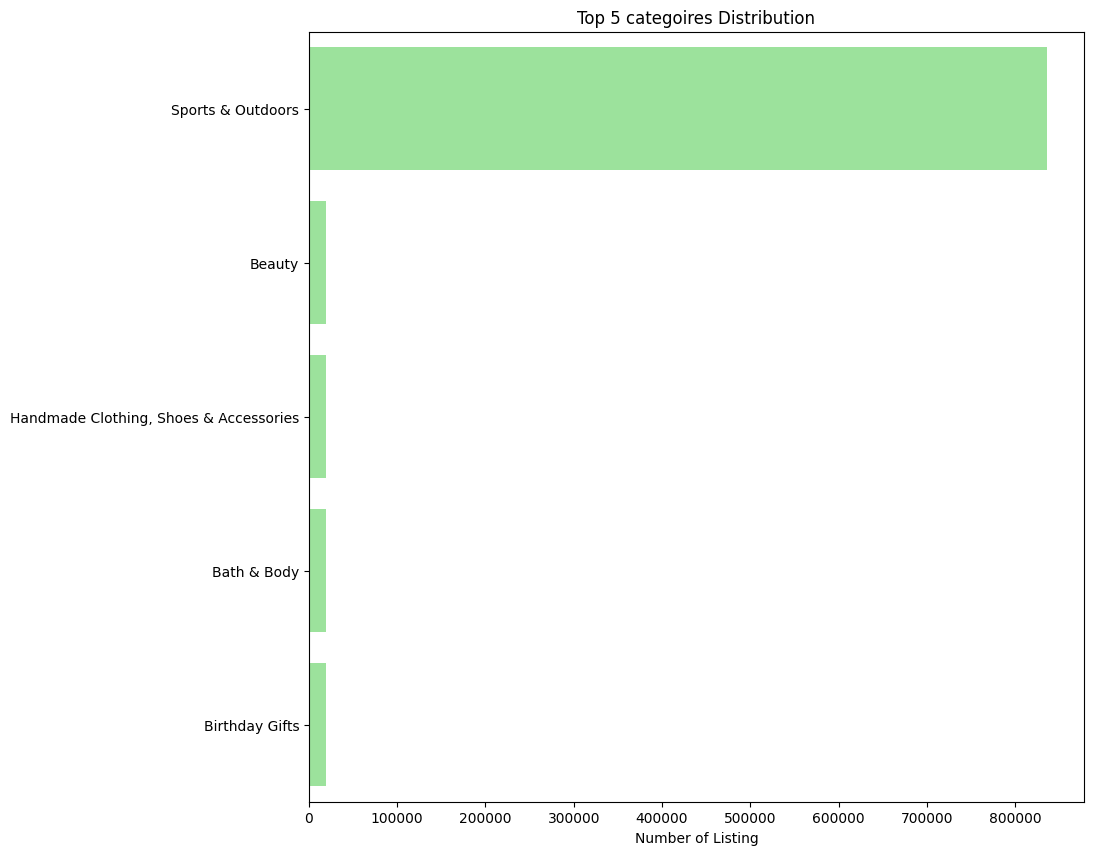

In [23]:
plt.figure(figsize=[10, 10])
sns.barplot( data= top_5_categories, x = "listing_count" , y = "category", color="lightgreen")
plt.title("Top 5 categoires Distribution")
plt.xlabel("Number of Listing")
plt.ylabel("")
# plt.xticks(rotation= 45)
plt.show()

**Key Insights**

- `Sports & Outdoors` category dominated and has more listings. This means more items related to `Sports & Outdoors` listings available to sell on website as compared to other categories.

**Problem 2: Delving into Product Pricing**

*Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?*

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [19]:
round(num_cols["price"].describe(), 2)

NameError: name 'num_cols' is not defined

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?


3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

***Key Observations***
- The **average product** price is **$89.24**, but this value is heavily influenced by very high-priced items.

- The **median price** is **$19.09**, which indicates that most products are priced well below the mean.

- The **standard deviation (345.61)** is very large relative to the mean, suggesting high price variability.

- **75% of products are priced below $45.99**, showing that the majority of listings are in the low-to-mid price range.

- The **maximum price of $100,000** is extremely high compared to the rest of the distribution and likely represents **outliers or special listings**.

- The **minimum price of $0.00** may indicate:
    - Free items
    - Missing or incorrectly recorded prices